In [ ]:
%pip install scikit-learn streamlit pandas numpy matplotlib seaborn plotly joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 28.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 53.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print(sns.__version__)

0.13.2


EDA

In [ ]:
df = pd.read_csv("new_retail_data.csv")
df.head()

,Transaction_ID,Customer_ID,Name,Email,Phone,Address,City,State,Zipcode,Country,...,Total_Amount,Product_Category,Product_Brand,Product_Type,Feedback,Shipping_Method,Payment_Method,Order_Status,Ratings,products
0,8691788.0,37249.0,Michelle Harrington,Ebony39@gmail.com,1.414787e+09,3959 Amanda Burgs,Dortmund,Berlin,77985.0,Germany,...,324.086270,Clothing,Nike,Shorts,Excellent,Same-Day,Debit Card,Shipped,5.0,Cycling shorts
1,2174773.0,69749.0,Kelsey Hill,Mark36@gmail.com,6.852900e+09,82072 Dawn Centers,Nottingham,England,99071.0,UK,...,806.707815,Electronics,Samsung,Tablet,Excellent,Standard,Credit Card,Processing,4.0,Lenovo Tab
2,6679610.0,30192.0,Scott Jensen,Shane85@gmail.com,8.362160e+09,4133 Young Canyon,Geelong,New South Wales,75929.0,Australia,...,1063.432799,Books,Penguin Books,Children's,Average,Same-Day,Credit Card,Processing,2.0,Sports equipment
3,7232460.0,62101.0,Joseph Miller,Mary34@gmail.com,2.776752e+09,8148 Thomas Creek Suite 100,Edmonton,Ontario,88420.0,Canada,...,2466.854021,Home Decor,Home Depot,Tools,Excellent,Standard,PayPal,Processing,4.0,Utility knife
4,4983775.0,27901.0,Debra Coleman,Charles30@gmail.com,9.098268e+09,5813 Lori Ports Suite 269,Bristol,England,48704.0,UK,...,248.553049,Grocery,Nestle,Chocolate,Bad,Standard,Cash,Shipped,1.0,Chocolate cookies


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302010 entries, 0 to 302009
Data columns (total 30 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Transaction_ID    301677 non-null  float64
 1   Customer_ID       301702 non-null  float64
 2   Name              301628 non-null  object 
 3   Email             301663 non-null  object 
 4   Phone             301648 non-null  float64
 5   Address           301695 non-null  object 
 6   City              301762 non-null  object 
 7   State             301729 non-null  object 
 8   Zipcode           301670 non-null  float64
 9   Country           301739 non-null  object 
 10  Age               301837 non-null  float64
 11  Gender            301693 non-null  object 
 12  Income            301720 non-null  object 
 13  Customer_Segment  301795 non-null  object 
 14  Date              301651 non-null  object 
 15  Year              301660 non-null  float64
 16  Month             30

In [ ]:
df.isna().sum()

,0
Transaction_ID,333
Customer_ID,308
Name,382
Email,347
Phone,362
Address,315
City,248
State,281
Zipcode,340
Country,271


In [ ]:
df.describe()

,Transaction_ID,Customer_ID,Phone,Zipcode,Age,Year,Total_Purchases,Amount,Total_Amount,Ratings
count,3.016770e+05,301702.000000,3.016480e+05,301670.000000,301837.000000,301660.000000,301649.000000,301653.000000,301660.000000,301826.000000
mean,5.495823e+06,55006.553934,5.501464e+09,50298.951019,35.481326,2023.165113,5.359729,255.163659,1367.651156,3.162670
std,2.595565e+06,26005.675200,2.596017e+09,28972.807134,15.021933,0.371283,2.868575,141.389640,1128.998515,1.320827
min,1.000007e+06,10000.000000,1.000049e+09,501.000000,18.000000,2023.000000,1.000000,10.000219,10.003750,1.000000
25%,3.247930e+06,32469.250000,3.255061e+09,25425.000000,22.000000,2023.000000,3.000000,132.890764,438.724278,2.000000
50%,5.499657e+06,55012.000000,5.505812e+09,50602.500000,32.000000,2023.000000,5.000000,255.470969,1041.117547,3.000000
75%,7.739509e+06,77511.000000,7.749860e+09,75252.000000,46.000000,2023.000000,8.000000,377.672606,2029.999853,4.000000
max,9.999995e+06,99999.000000,9.999996e+09,99949.000000,70.000000,2024.000000,10.000000,499.997911,4999.625796,5.000000


Create the target

Bad or Average feedback becomes 1 (dissatisfied). Good or Excellent becomes 0 (satisfied).

In [ ]:
df['Feedback'].value_counts()

,count
Feedback,
Excellent,100755
Good,95098
Average,62674
Bad,43299


In [ ]:
df = df.dropna(subset=['Feedback'])
df['Dissatisfied'] = df['Feedback'].isin(['Bad', 'Average']).astype(int)
df['Dissatisfied'].value_counts()

,count
Dissatisfied,
0,195853
1,105973


In [ ]:
df = df[['Dissatisfied',
         'Age',
         'Gender',
         'Income',
         'Customer_Segment',
         'Country',
         'Month',
         'Total_Purchases',
         'Amount',
         'Total_Amount',
         'Product_Category',
         'Shipping_Method',
         'Payment_Method',
         'Order_Status']]

df.head()

,Dissatisfied,Age,Gender,Income,Customer_Segment,Country,Month,Total_Purchases,Amount,Total_Amount,Product_Category,Shipping_Method,Payment_Method,Order_Status
0,0,21.0,Male,Low,Regular,Germany,September,3.0,108.028757,324.086270,Clothing,Same-Day,Debit Card,Shipped
1,0,19.0,Female,Low,Premium,UK,December,2.0,403.353907,806.707815,Electronics,Standard,Credit Card,Processing
2,1,48.0,Male,Low,Regular,Australia,April,3.0,354.477600,1063.432799,Books,Same-Day,Credit Card,Processing
3,0,56.0,Male,High,Premium,Canada,May,7.0,352.407717,2466.854021,Home Decor,Standard,PayPal,Processing
4,1,22.0,Male,Low,Premium,UK,January,2.0,124.276524,248.553049,Grocery,Standard,Cash,Shipped


In [ ]:
df_new = df.copy()

Clean the data

In [ ]:
df_new.isna().sum()

,0
Dissatisfied,0
Age,173
Gender,317
Income,290
Customer_Segment,215
Country,271
Month,273
Total_Purchases,361
Amount,357
Total_Amount,350


In [ ]:
num_cols = ['Age', 'Total_Purchases', 'Amount', 'Total_Amount']
cat_cols = ['Gender', 'Income', 'Customer_Segment', 'Country', 'Month',
            'Product_Category', 'Shipping_Method', 'Payment_Method', 'Order_Status']

for col in num_cols:
    df_new[col] = df_new[col].fillna(df_new[col].median())
for col in cat_cols:
    df_new[col] = df_new[col].fillna(df_new[col].mode()[0])

df_new.isna().sum()

,0
Dissatisfied,0
Age,0
Gender,0
Income,0
Customer_Segment,0
Country,0
Month,0
Total_Purchases,0
Amount,0
Total_Amount,0


Plots

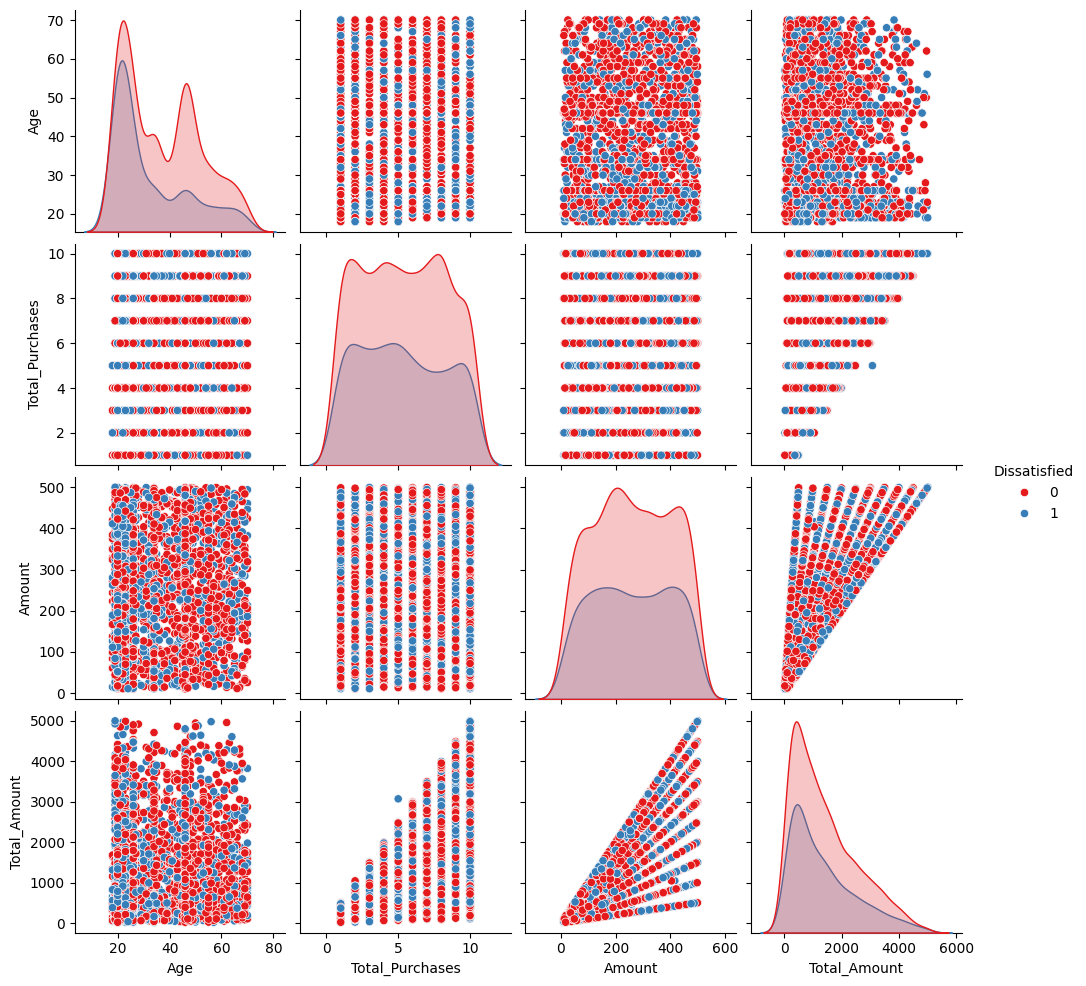

In [ ]:
sns.pairplot(df_new.sample(3000, random_state=42), hue='Dissatisfied', palette='Set1')

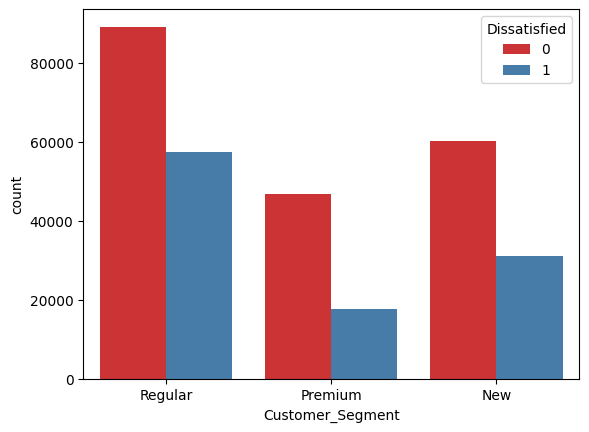

In [ ]:
sns.countplot(x='Customer_Segment', hue='Dissatisfied', data=df_new, palette='Set1')
plt.show()

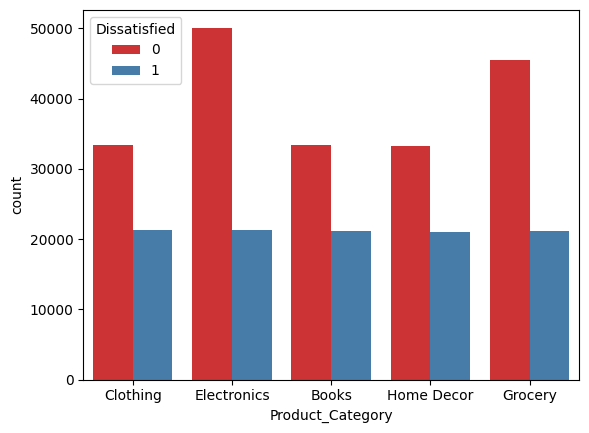

In [ ]:
sns.countplot(x='Product_Category', hue='Dissatisfied', data=df_new, palette='Set1')
plt.show()

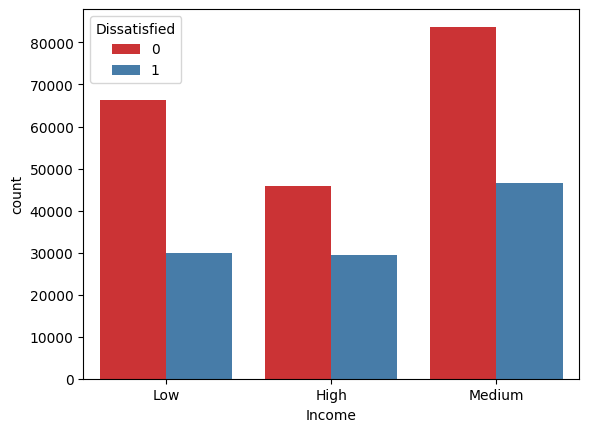

In [ ]:
sns.countplot(x='Income', hue='Dissatisfied', data=df_new, palette='Set1')
plt.show()

In [ ]:
px.histogram(df_new, x='Total_Amount', color='Dissatisfied',
             marginal='box', nbins=30,
             title='Total Transaction Amount Distribution by Dissatisfaction')

Split input and output

In [ ]:
X = df_new.drop('Dissatisfied', axis=1)
y = df_new['Dissatisfied']
X

,Age,Gender,Income,Customer_Segment,Country,Month,Total_Purchases,Amount,Total_Amount,Product_Category,Shipping_Method,Payment_Method,Order_Status
0,21.0,Male,Low,Regular,Germany,September,3.0,108.028757,324.086270,Clothing,Same-Day,Debit Card,Shipped
1,19.0,Female,Low,Premium,UK,December,2.0,403.353907,806.707815,Electronics,Standard,Credit Card,Processing
2,48.0,Male,Low,Regular,Australia,April,3.0,354.477600,1063.432799,Books,Same-Day,Credit Card,Processing
3,56.0,Male,High,Premium,Canada,May,7.0,352.407717,2466.854021,Home Decor,Standard,PayPal,Processing
4,22.0,Male,Low,Premium,UK,January,2.0,124.276524,248.553049,Grocery,Standard,Cash,Shipped
...,...,...,...,...,...,...,...,...,...,...,...,...,...
302005,31.0,Male,Medium,Regular,Australia,January,5.0,194.792597,973.962984,Books,Same-Day,Cash,Processing
302006,35.0,Female,Low,New,Germany,December,1.0,285.137301,285.137301,Electronics,Same-Day,Cash,Processing
302007,41.0,Male,Low,Premium,UK,February,3.0,60.701761,182.105285,Clothing,Express,Cash,Shipped
302008,41.0,Male,Medium,New,Canada,September,1.0,120.834784,120.834784,Home Decor,Standard,Cash,Shipped


In [ ]:
X['Customer_Segment'].value_counts()

,count
Customer_Segment,
Regular,146319
New,91144
Premium,64363


In [ ]:
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)
X

,Age,Total_Purchases,Amount,Total_Amount,Gender_Male,Income_Low,Income_Medium,Customer_Segment_Premium,Customer_Segment_Regular,Country_Canada,...,Product_Category_Grocery,Product_Category_Home Decor,Shipping_Method_Same-Day,Shipping_Method_Standard,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_PayPal,Order_Status_Pending,Order_Status_Processing,Order_Status_Shipped
0,21.0,3.0,108.028757,324.086270,1,1,0,0,1,0,...,0,0,1,0,0,1,0,0,0,1
1,19.0,2.0,403.353907,806.707815,0,1,0,1,0,0,...,0,0,0,1,1,0,0,0,1,0
2,48.0,3.0,354.477600,1063.432799,1,1,0,0,1,0,...,0,0,1,0,1,0,0,0,1,0
3,56.0,7.0,352.407717,2466.854021,1,0,0,1,0,1,...,0,1,0,1,0,0,1,0,1,0
4,22.0,2.0,124.276524,248.553049,1,1,0,1,0,0,...,1,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302005,31.0,5.0,194.792597,973.962984,1,0,1,0,1,0,...,0,0,1,0,0,0,0,0,1,0
302006,35.0,1.0,285.137301,285.137301,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
302007,41.0,3.0,60.701761,182.105285,1,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
302008,41.0,1.0,120.834784,120.834784,1,0,1,0,0,1,...,0,1,0,1,0,0,0,0,0,1


Split the data into train and test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Apply scaling

In [ ]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

Apply the modeling

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

lr = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)
print("Classification report training:\n",
      classification_report(y_train, lr.predict(X_train_scaled)))
print("Classification report testing:\n",
      classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.74      0.58      0.65    156682
           1       0.45      0.62      0.52     84778

    accuracy                           0.60    241460
   macro avg       0.59      0.60      0.59    241460
weighted avg       0.64      0.60      0.60    241460

Classification report testing:
               precision    recall  f1-score   support

           0       0.74      0.58      0.65     39171
           1       0.45      0.63      0.52     21195

    accuracy                           0.60     60366
   macro avg       0.59      0.60      0.59     60366
weighted avg       0.64      0.60      0.60     60366



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_scaled, y_train)

# KNN is slow on 240k rows, so evaluate on a 20,000-row sample
rng = np.random.RandomState(42)
tr_idx = rng.choice(len(X_train_scaled), 20000, replace=False)
te_idx = rng.choice(len(X_test_scaled), 20000, replace=False)

print("Classification report training:\n",
      classification_report(y_train.iloc[tr_idx], knn.predict(X_train_scaled[tr_idx])))
print("Classification report testing:\n",
      classification_report(y_test.iloc[te_idx], knn.predict(X_test_scaled[te_idx])))

Classification report training:
               precision    recall  f1-score   support

           0       0.77      0.87      0.81     12899
           1       0.68      0.53      0.60      7101

    accuracy                           0.75     20000
   macro avg       0.73      0.70      0.70     20000
weighted avg       0.74      0.75      0.74     20000

Classification report testing:
               precision    recall  f1-score   support

           0       0.69      0.77      0.73     13044
           1       0.45      0.35      0.39      6956

    accuracy                           0.62     20000
   macro avg       0.57      0.56      0.56     20000
weighted avg       0.60      0.62      0.61     20000



In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42, max_depth=5, class_weight='balanced')
dt.fit(X_train_scaled, y_train)
y_pred = dt.predict(X_test_scaled)
print("Classification report training:\n",
      classification_report(y_train, dt.predict(X_train_scaled)))
print("Classification report testing:\n",
      classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.75      0.61      0.67    156682
           1       0.46      0.62      0.53     84778

    accuracy                           0.61    241460
   macro avg       0.61      0.62      0.60    241460
weighted avg       0.65      0.61      0.62    241460

Classification report testing:
               precision    recall  f1-score   support

           0       0.75      0.61      0.67     39171
           1       0.46      0.62      0.53     21195

    accuracy                           0.61     60366
   macro avg       0.60      0.61      0.60     60366
weighted avg       0.65      0.61      0.62     60366



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5,
                            class_weight='balanced', n_jobs=-1)
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)
print("Classification report training:\n",
      classification_report(y_train, rf.predict(X_train_scaled)))
print("Classification report testing:\n",
      classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.75      0.66      0.70    156682
           1       0.49      0.60      0.54     84778

    accuracy                           0.64    241460
   macro avg       0.62      0.63      0.62    241460
weighted avg       0.66      0.64      0.64    241460

Classification report testing:
               precision    recall  f1-score   support

           0       0.75      0.65      0.70     39171
           1       0.48      0.60      0.54     21195

    accuracy                           0.63     60366
   macro avg       0.62      0.63      0.62     60366
weighted avg       0.66      0.63      0.64     60366



Cross validation

In [ ]:
from sklearn.model_selection import KFold, cross_validate

kf = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_validate(rf, X_train_scaled, y_train, cv=kf,
                        scoring='f1_macro', return_train_score=True)
print("mean train f1:", scores['train_score'].mean())
print("mean test  f1:", scores['test_score'].mean())

mean train f1: 0.6192096214329337
mean test  f1: 0.6187060508833268


Hyperparameter tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
    param_grid,
    cv=3,
    scoring='f1_macro'
)
grid_search.fit(X_train_scaled, y_train)
grid_search.best_params_

{'max_depth': 15, 'n_estimators': 200}

In [ ]:
best = grid_search.best_params_
rf = RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1, **best)
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)
print("Classification report training:\n", classification_report(y_train, rf.predict(X_train_scaled)))
print("Classification report testing:\n", classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.87      0.69      0.77    156682
           1       0.59      0.82      0.68     84778

    accuracy                           0.73    241460
   macro avg       0.73      0.75      0.73    241460
weighted avg       0.77      0.73      0.74    241460

Classification report testing:
               precision    recall  f1-score   support

           0       0.78      0.62      0.69     39171
           1       0.49      0.67      0.57     21195

    accuracy                           0.64     60366
   macro avg       0.63      0.65      0.63     60366
weighted avg       0.68      0.64      0.65     60366



Create the pipeline for deployment

In [ ]:
X = df.drop('Dissatisfied', axis=1)
y = df['Dissatisfied']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numerical_columns = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_columns = X_train.select_dtypes(exclude=['number']).columns
print(numerical_columns)
print(cat_columns)

for col in cat_columns:
    print(col, ':', X_train[col].dropna().unique())

Index(['Age', 'Total_Purchases', 'Amount', 'Total_Amount'], dtype='object')
Index(['Gender', 'Income', 'Customer_Segment', 'Country', 'Month',
       'Product_Category', 'Shipping_Method', 'Payment_Method',
       'Order_Status'],
      dtype='object')
Gender : ['Female' 'Male']
Income : ['Low' 'Medium' 'High']
Customer_Segment : ['Premium' 'Regular' 'New']
Country : ['Australia' 'Canada' 'USA' 'UK' 'Germany']
Month : ['July' 'January' 'May' 'June' 'April' 'August' 'February' 'December'
 'March' 'November' 'September' 'October']
Product_Category : ['Books' 'Grocery' 'Clothing' 'Electronics' 'Home Decor']
Shipping_Method : ['Express' 'Same-Day' 'Standard']
Payment_Method : ['PayPal' 'Credit Card' 'Debit Card' 'Cash']
Order_Status : ['Delivered' 'Shipped' 'Pending' 'Processing']


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', cat_pipeline, cat_columns)
], remainder='passthrough')

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1, **best))
])

final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.62      0.69     39171
           1       0.49      0.67      0.56     21195

    accuracy                           0.64     60366
   macro avg       0.63      0.64      0.63     60366
weighted avg       0.67      0.64      0.64     60366



In [ ]:
import joblib
joblib.dump(final_pipeline, 'satisfaction_model.pkl', compress=3)
classifier = joblib.load('satisfaction_model.pkl')

In [ ]:
classifier.predict(pd.DataFrame([{
    'Age': 30,
    'Gender': 'Male',
    'Income': 'Medium',
    'Customer_Segment': 'Regular',
    'Country': 'USA',
    'Month': 'May',
    'Total_Purchases': 3,
    'Amount': 250.0,
    'Total_Amount': 750.0,
    'Product_Category': 'Electronics',
    'Shipping_Method': 'Express',
    'Payment_Method': 'Credit Card',
    'Order_Status': 'Delivered'
}]))

array([0])

Streamlit app

In [ ]:
%%writefile app.py

import streamlit as st
import joblib
import pandas as pd

classifier = joblib.load('satisfaction_model.pkl')

def predict_dissatisfaction(Age, Gender, Income, Customer_Segment, Country, Month,
                            Total_Purchases, Amount, Product_Category,
                            Shipping_Method, Payment_Method, Order_Status):
    input_data = pd.DataFrame([{
        'Age': Age,
        'Gender': Gender,
        'Income': Income,
        'Customer_Segment': Customer_Segment,
        'Country': Country,
        'Month': Month,
        'Total_Purchases': Total_Purchases,
        'Amount': Amount,
        'Total_Amount': Total_Purchases * Amount,
        'Product_Category': Product_Category,
        'Shipping_Method': Shipping_Method,
        'Payment_Method': Payment_Method,
        'Order_Status': Order_Status
    }])
    prediction = classifier.predict(input_data)
    proba = classifier.predict_proba(input_data)[0][1]
    label = 'Customer Will Be Dissatisfied' if prediction[0] == 1 else 'Customer Will Be Satisfied'
    return label, proba

def main():
    st.title("Customer Satisfaction Prediction")
    html_temp = """
        <div style="background-color:red;padding:10px">
            <h2 style="color:white;text-align:center;">This our Streamlit Deployment App</h2>
        </div>
        """
    st.markdown(html_temp, unsafe_allow_html=True)
    st.write("Enter transaction details to predict whether the customer will be dissatisfied.")

    Age = st.number_input("Age", min_value=18, max_value=100, value=30)
    Gender = st.selectbox("Gender", ['Male', 'Female'])
    Income = st.selectbox("Income", ['Low', 'Medium', 'High'])
    Customer_Segment = st.selectbox("Customer Segment", ['New', 'Regular', 'Premium'])
    Country = st.selectbox("Country", ['USA', 'UK', 'Germany', 'Canada', 'Australia'])
    Month = st.selectbox("Month", ['January', 'February', 'March', 'April', 'May', 'June',
                                   'July', 'August', 'September', 'October', 'November', 'December'])
    Total_Purchases = st.number_input("Total Purchases (items)", min_value=1, max_value=10, value=3)
    Amount = st.number_input("Amount per item", min_value=0.0, value=250.0, format="%.2f")
    Product_Category = st.selectbox("Product Category", ['Electronics', 'Grocery', 'Clothing', 'Books', 'Home Decor'])
    Shipping_Method = st.selectbox("Shipping Method", ['Same-Day', 'Express', 'Standard'])
    Payment_Method = st.selectbox("Payment Method", ['Credit Card', 'Debit Card', 'Cash', 'PayPal'])
    Order_Status = st.selectbox("Order Status", ['Delivered', 'Shipped', 'Processing', 'Pending'])

    st.write(f"Total Amount: {Total_Purchases * Amount:,.2f}")

    if st.button("Predict"):
        result, proba = predict_dissatisfaction(
            Age, Gender, Income, Customer_Segment, Country, Month,
            Total_Purchases, Amount, Product_Category,
            Shipping_Method, Payment_Method, Order_Status
        )
        st.success(f"Prediction: {result}")
        st.write(f"Probability of dissatisfaction: {proba:.1%}")

if __name__ == '__main__':
    main()

Overwriting app.py


To start the app, run this in a terminal from the same folder:

In [ ]:
!pkill -f streamlit
!streamlit run app.py --server.port 8501 --server.headless true &>/content/logs.txt &

In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!./cloudflared tunnel --url http://localhost:8501 2>&1 | grep -o "https://.*trycloudflare.com"

https://fireplace-composite-app-isp.trycloudflare.com


In [2]:
import pandas as pd, numpy as np, joblib, sys
import sklearn, streamlit
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# load + target
df = pd.read_csv("new_retail_data.csv")
df = df.dropna(subset=['Feedback'])
df['Dissatisfied'] = df['Feedback'].isin(['Bad', 'Average']).astype(int)

cols = ['Age', 'Gender', 'Income', 'Customer_Segment', 'Country', 'Month',
        'Total_Purchases', 'Amount', 'Total_Amount', 'Product_Category',
        'Shipping_Method', 'Payment_Method', 'Order_Status']
X = df[cols]
y = df['Dissatisfied']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

numerical_columns = X_train.select_dtypes(include=['number']).columns
cat_columns = X_train.select_dtypes(exclude=['number']).columns

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler(with_mean=False))]), numerical_columns),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cat_columns)
])

# smaller model (~9 MB) so it fits on GitHub
small_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=12,
                                  class_weight='balanced', random_state=42, n_jobs=-1))
])
small_pipeline.fit(X_train, y_train)
print(classification_report(y_test, small_pipeline.predict(X_test)))
joblib.dump(small_pipeline, 'satisfaction_model.pkl', compress=9)

# requirements.txt with Colab's exact versions
with open('requirements.txt', 'w') as f:
    f.write(f"streamlit=={streamlit.__version__}\n")
    f.write(f"scikit-learn=={sklearn.__version__}\n")
    f.write(f"pandas=={pd.__version__}\n")
    f.write(f"numpy=={np.__version__}\n")
    f.write("joblib\n")

print(open('requirements.txt').read())
print("Python version:", sys.version.split()[0])

              precision    recall  f1-score   support

           0       0.78      0.60      0.68     39171
           1       0.48      0.69      0.57     21195

    accuracy                           0.63     60366
   macro avg       0.63      0.65      0.63     60366
weighted avg       0.68      0.63      0.64     60366

streamlit==1.67.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib

Python version: 3.13.18


In [3]:
print(open('app.py').read()[:300])


import streamlit as st
import joblib
import pandas as pd

classifier = joblib.load('satisfaction_model.pkl')

def predict_dissatisfaction(Age, Gender, Income, Customer_Segment, Country, Month,
                            Total_Purchases, Amount, Product_Category,
                            Shippin


In [2]:
import pandas as pd, numpy as np, joblib, sys, os
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from google.colab import files

# load data + target
df = pd.read_csv("new_retail_data.csv")
df = df.dropna(subset=['Feedback'])
df['Dissatisfied'] = df['Feedback'].isin(['Bad', 'Average']).astype(int)

cols = ['Age', 'Gender', 'Income', 'Customer_Segment', 'Country', 'Month',
        'Total_Purchases', 'Amount', 'Total_Amount', 'Product_Category',
        'Shipping_Method', 'Payment_Method', 'Order_Status']
X = df[cols]
y = df['Dissatisfied']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(exclude=['number']).columns

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler(with_mean=False))]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cat_cols)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=12,
                                  class_weight='balanced', random_state=42, n_jobs=-1))
])
model.fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))

# save
joblib.dump(model, 'satisfaction_model.pkl', compress=9)

# check the saved file loads correctly
test = joblib.load('satisfaction_model.pkl')
print("Model reloads OK, test prediction:", test.predict(X_test.head(1)))
print("File size:", round(os.path.getsize('satisfaction_model.pkl') / 1e6, 1), "MB")
print("scikit-learn version:", sklearn.__version__)

# download to your computer
files.download('satisfaction_model.pkl')

              precision    recall  f1-score   support

           0       0.78      0.60      0.68     39171
           1       0.48      0.69      0.57     21195

    accuracy                           0.63     60366
   macro avg       0.63      0.65      0.63     60366
weighted avg       0.68      0.63      0.64     60366

Model reloads OK, test prediction: [0]
File size: 12.5 MB
scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>